Dataset root: /content/drive/.shortcut-targets-by-id/1acU-wiKH9ar7uTmg3m8-v2aAtEvT4k9e/task_mongolia
Epoch 01/55 | Val MAE: 17.620 (best: 17.620)
Epoch 05/55 | Val MAE: 10.718 (best: 10.718)
Epoch 10/55 | Val MAE: 8.558 (best: 7.271)
Epoch 15/55 | Val MAE: 8.666 (best: 5.583)
Epoch 20/55 | Val MAE: 7.317 (best: 5.451)
Epoch 25/55 | Val MAE: 6.230 (best: 5.139)
Epoch 30/55 | Val MAE: 13.226 (best: 4.544)
Epoch 35/55 | Val MAE: 4.606 (best: 4.544)
Epoch 40/55 | Val MAE: 3.881 (best: 3.881)
Epoch 45/55 | Val MAE: 4.875 (best: 3.747)
Epoch 50/55 | Val MAE: 3.648 (best: 3.522)
Epoch 55/55 | Val MAE: 3.462 (best: 3.384)
Saved /content/counts.csv (333 rows), total predicted sheep: 12298
Saved /content/survey_flag_map.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

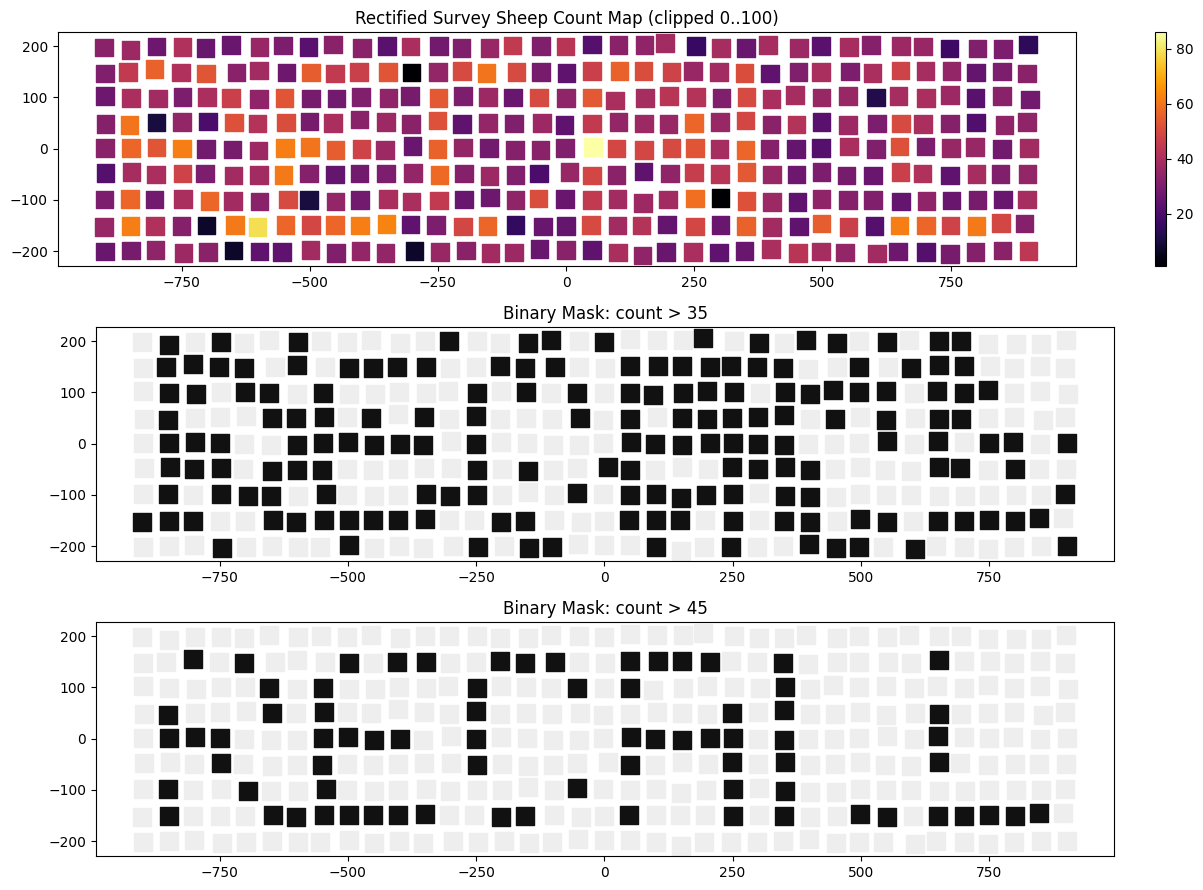

In [5]:
"""
Mongolia — O sarcină bee-ton! (Drone Sheep Counting & Spatial Flag Recovery)
Run in Google Colab (GPU T4 recommended).
1. Locates the Mongolia dataset in mounted Drive (following shortcuts/symlinks) OR
   downloads all 616 files directly via Colab Drive API.
2. Trains a ResNet34-UNet density-map counter (Softplus output + 100x scaled density)
   for 55 epochs supervised by train_points.csv (11,629 points).
3. Evaluates Val MAE, predicts counts on all 333 survey/*.jpg images, and saves counts.csv.
4. Rectifies the tilted 9x37 survey grid via PCA and plots crisp heatmaps to reveal SIGMOID_<WORD>.
"""
import io
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.ndimage import gaussian_filter
from torch.utils.data import DataLoader, Dataset
from torchvision import models

FOLDER_ID = "1acU-wiKH9ar7uTmg3m8-v2aAtEvT4k9e"
DENSITY_SCALE = 100.0


def _find_in_tree(base: Path, target: str = "train_counts.csv") -> Path | None:
    if not base.exists():
        return None
    for dirpath, _, filenames in os.walk(base, followlinks=True):
        if target in filenames:
            return Path(dirpath)
    return None


def _download_via_colab_drive_api(dest: Path) -> Path:
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload

    auth.authenticate_user()
    service = build("drive", "v3")

    def list_children(parent_id: str) -> list[dict]:
        items, page_token = [], None
        while True:
            resp = (
                service.files()
                .list(
                    q=f"'{parent_id}' in parents and trashed=false",
                    fields="nextPageToken, files(id, name, mimeType)",
                    pageSize=1000,
                    pageToken=page_token,
                )
                .execute()
            )
            items.extend(resp.get("files", []))
            page_token = resp.get("nextPageToken")
            if not page_token:
                break
        return items

    def download_file(file_id: str, out_path: Path) -> None:
        if out_path.exists() and out_path.stat().st_size > 0:
            return
        svc = build("drive", "v3")
        req = svc.files().get_media(fileId=file_id)
        buf = io.BytesIO()
        downloader = MediaIoBaseDownload(buf, req)
        done = False
        while not done:
            _, done = downloader.next_chunk()
        out_path.write_bytes(buf.getvalue())

    dest.mkdir(parents=True, exist_ok=True)
    tasks: list[tuple[str, Path]] = []
    for item in list_children(FOLDER_ID):
        if item["mimeType"] == "application/vnd.google-apps.folder":
            sub_dir = dest / item["name"]
            sub_dir.mkdir(parents=True, exist_ok=True)
            for child in list_children(item["id"]):
                tasks.append((child["id"], sub_dir / child["name"]))
        else:
            tasks.append((item["id"], dest / item["name"]))

    print(f"Downloading {len(tasks)} files from Google Drive into {dest}...")
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(lambda args: download_file(*args), tasks))
    return dest


def ensure_data() -> Path:
    for candidate in [
        Path("/content/task_mongolia"),
        Path("/content"),
        Path(f"/content/drive/.shortcut-targets-by-id/{FOLDER_ID}"),
        Path("/content/drive/MyDrive"),
    ]:
        found = _find_in_tree(candidate)
        if found is not None:
            return found

    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        for candidate in [
            Path(f"/content/drive/.shortcut-targets-by-id/{FOLDER_ID}"),
            Path("/content/drive/MyDrive"),
        ]:
            found = _find_in_tree(candidate)
            if found is not None:
                return found
    except ImportError:
        pass

    return _download_via_colab_drive_api(Path("/content/task_mongolia"))


def make_density_map(h: int, w: int, pts: np.ndarray, sigma: float = 4.0) -> np.ndarray:
    dmap = np.zeros((h, w), dtype=np.float32)
    for x, y in pts:
        xi = int(np.clip(round(x), 0, w - 1))
        yi = int(np.clip(round(y), 0, h - 1))
        dmap[yi, xi] += 1.0
    if len(pts) > 0:
        dmap = gaussian_filter(dmap, sigma=sigma, mode="constant")
        s = dmap.sum()
        if s > 0:
            dmap *= (len(pts) * DENSITY_SCALE) / s
    return dmap


class SheepDataset(Dataset):
    def __init__(self, img_dir: Path, df: pd.DataFrame, points_map: dict[str, np.ndarray] | None = None, augment: bool = False):
        self.img_dir = img_dir
        self.df = df.reset_index(drop=True)
        self.points_map = points_map
        self.augment = augment
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        name = row["image"]
        img = np.array(Image.open(self.img_dir / name).convert("RGB"), dtype=np.float32) / 255.0
        h, w, _ = img.shape

        if self.points_map is None:
            x = (img - self.mean) / self.std
            return torch.from_numpy(x).permute(2, 0, 1), name

        pts = self.points_map.get(name, np.zeros((0, 2), dtype=np.float32)).copy()
        if self.augment:
            if np.random.rand() < 0.5:
                img = np.fliplr(img).copy()
                if len(pts):
                    pts[:, 0] = (w - 1) - pts[:, 0]
            if np.random.rand() < 0.5:
                img = np.flipud(img).copy()
                if len(pts):
                    pts[:, 1] = (h - 1) - pts[:, 1]
            k = np.random.randint(0, 4)
            if k:
                img = np.rot90(img, k).copy()
                for _ in range(k):
                    if len(pts):
                        nx = pts[:, 1].copy()
                        ny = (w - 1) - pts[:, 0].copy()
                        pts[:, 0], pts[:, 1] = nx, ny

        dmap = make_density_map(h, w, pts, sigma=4.0)
        dmap_4x = dmap.reshape(h // 4, 4, w // 4, 4).sum(axis=(1, 3))
        x = (img - self.mean) / self.std
        return (
            torch.from_numpy(x).permute(2, 0, 1),
            torch.from_numpy(dmap_4x).unsqueeze(0),
            torch.tensor(float(row["count"]), dtype=torch.float32),
        )


class ResNet34DensityNet(nn.Module):
    def __init__(self):
        super().__init__()
        backbone = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        self.up4 = nn.Conv2d(512, 256, 1)
        self.up3 = nn.Conv2d(256, 128, 1)
        self.up2 = nn.Conv2d(128, 64, 1)
        self.head = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1),
            nn.Softplus(),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        f1 = self.layer1(x)
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)

        d3 = F.interpolate(self.up4(f4), size=f3.shape[-2:], mode="bilinear", align_corners=False) + f3
        d2 = F.interpolate(self.up3(d3), size=f2.shape[-2:], mode="bilinear", align_corners=False) + f2
        d1 = F.interpolate(self.up2(d2), size=f1.shape[-2:], mode="bilinear", align_corners=False) + f1
        return self.head(d1)


def main() -> None:
    root = ensure_data()
    print("Dataset root:", root)

    tc = pd.read_csv(root / "train_counts.csv")
    tp = pd.read_csv(root / "train_points.csv")
    sp = pd.read_csv(root / "survey_plots.csv")

    points_map = {
        img: grp[["x", "y"]].to_numpy(dtype=np.float32)
        for img, grp in tp.groupby("image")
    }

    rng = np.random.default_rng(42)
    perm = rng.permutation(len(tc))
    val_n = int(0.2 * len(tc))
    val_df = tc.iloc[perm[:val_n]]
    trn_df = tc.iloc[perm[val_n:]]

    trn_loader = DataLoader(SheepDataset(root / "train", trn_df, points_map, augment=True), batch_size=8, shuffle=True, num_workers=2)
    val_loader = DataLoader(SheepDataset(root / "train", val_df, points_map, augment=False), batch_size=8, shuffle=False, num_workers=2)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ResNet34DensityNet().to(device)
    epochs = 55
    optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_mae = 1e9
    best_path = Path("/content/best_sheep_model.pt")

    for epoch in range(1, epochs + 1):
        model.train()
        for imgs, dmaps, counts in trn_loader:
            imgs, dmaps, counts = imgs.to(device), dmaps.to(device), counts.to(device)
            preds = model(imgs)
            pred_counts = preds.sum(dim=(1, 2, 3)) / DENSITY_SCALE
            loss = F.mse_loss(preds, dmaps) + 0.05 * F.l1_loss(pred_counts, counts)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()

        model.eval()
        abs_errs = []
        with torch.no_grad():
            for imgs, _, counts in val_loader:
                imgs = imgs.to(device)
                pred_counts = (model(imgs).sum(dim=(1, 2, 3)) / DENSITY_SCALE).cpu().numpy()
                abs_errs.extend(np.abs(pred_counts - counts.numpy()))
        mae = float(np.mean(abs_errs))
        if mae < best_mae:
            best_mae = mae
            torch.save(model.state_dict(), best_path)
        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:02d}/{epochs} | Val MAE: {mae:.3f} (best: {best_mae:.3f})")

    model.load_state_dict(torch.load(best_path, map_location=device))
    model.eval()
    test_loader = DataLoader(SheepDataset(root / "survey", sp[["image"]]), batch_size=16, shuffle=False, num_workers=2)
    preds_list = []
    with torch.no_grad():
        for imgs, names in test_loader:
            imgs = imgs.to(device)
            cnts = (model(imgs).sum(dim=(1, 2, 3)) / DENSITY_SCALE).cpu().numpy()
            for name, c in zip(names, cnts):
                preds_list.append({"image": name, "count": int(round(max(0.0, float(c))))})

    out_df = pd.DataFrame(preds_list).sort_values("image")
    out_csv = Path("/content/counts.csv")
    out_df.to_csv(out_csv, index=False)
    print(f"Saved {out_csv} ({len(out_df)} rows), total predicted sheep: {out_df['count'].sum()}")

    # PCA-rectified 9x37 grid visualization
    merged = sp.merge(out_df, on="image")
    coords = merged[["x_m", "y_m"]].to_numpy()
    centered = coords - coords.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    rot = centered @ vt.T
    if rot[:, 0].max() - rot[:, 0].min() < rot[:, 1].max() - rot[:, 1].min():
        rot = rot[:, ::-1]
    # Ensure left-to-right matches increasing x_m
    if np.corrcoef(rot[:, 0], merged["x_m"])[0, 1] < 0:
        rot[:, 0] = -rot[:, 0]
    if np.corrcoef(rot[:, 1], merged["y_m"])[0, 1] < 0:
        rot[:, 1] = -rot[:, 1]

    fig, axes = plt.subplots(3, 1, figsize=(16, 9))
    sc0 = axes[0].scatter(rot[:, 0], rot[:, 1], c=np.clip(merged["count"], 0, 100), cmap="inferno", s=160, marker="s")
    axes[0].set_title("Rectified Survey Sheep Count Map (clipped 0..100)")
    axes[0].set_aspect("equal")
    plt.colorbar(sc0, ax=axes[0])

    for ax, thresh in zip(axes[1:], [35, 45]):
        high = merged["count"] > thresh
        ax.scatter(rot[~high, 0], rot[~high, 1], c="#eeeeee", s=160, marker="s")
        ax.scatter(rot[high, 0], rot[high, 1], c="#111111", s=160, marker="s")
        ax.set_title(f"Binary Mask: count > {thresh}")
        ax.set_aspect("equal")

    out_png = Path("/content/survey_flag_map.png")
    fig.tight_layout()
    fig.savefig(out_png, dpi=150)
    print(f"Saved {out_png}")

    try:
        from google.colab import files
        files.download(str(out_csv))
        files.download(str(out_png))
    except ImportError:
        pass


if __name__ == "__main__":
    main()